### Learning and Exploring how to handle Audio in python..

##### Libs used:
```text
faster-whisper==1.2.1
fastapi==0.136.3
librosa==0.11.0
sounddevice==0.5.5
soundfile==0.14.0
torch==2.12.0
torchaudio==2.11.0
pandas==3.0.3
matplotlib==3.11.0
seaborn==0.13.2

```

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline


In [2]:
from glob import glob

import librosa
import librosa.display
import IPython.display as ipd

from itertools import cycle

sns.set_theme(style="white", palette=None)
color_pal = plt.rcParams["axes.prop_cycle"].by_key()["color"]
color_cycle = cycle(plt.rcParams["axes.prop_cycle"].by_key()["color"])

In [3]:
audio_files = sorted(glob("../assets/*/*.wav"))
print(f"found {len(audio_files)} audio files")

found 1440 audio files


In [4]:
# ipd.Audio(audio_files[0])
if audio_files:
    ipd.display(ipd.Audio(audio_files[0]))
    print(f"Loaded file: {audio_files[0]}")
else:
    print("audio_files is empty..")

Loaded file: ../assets/Actor_01/03-01-01-01-01-01-01.wav


In [5]:
audio_files[0]

'../assets/Actor_01/03-01-01-01-01-01-01.wav'

In [6]:
y, sr = librosa.load(audio_files[0])
print(f"y: {y.shape} \n {y[:15]}")
print(f"y: {sr}")

/home/kradarsh/Desktop/Projects/voice_assistant/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


y: (72838,) 
 [ 5.3765323e-08 -2.1233109e-08 -6.0478840e-09  3.8985974e-08
 -7.6543159e-08  1.1907764e-07 -1.6708483e-07  2.2135779e-07
 -2.8319059e-07  3.5470674e-07 -4.3946528e-07  5.4361374e-07
 -6.7830700e-07  8.6537625e-07 -1.1528285e-06]
y: 22050


In [7]:
# pd.Series(y).plot(kind='bar')
pd.Series(y).plot(figsize=(10,5), title='Raw Audio', ylabel='Amplitude')

SyntaxError: invalid syntax (1372907379.py, line 2)

In [ ]:
pd.Series(y).info()

Text(0.5, 1.0, 'Waveform (trimmed)')

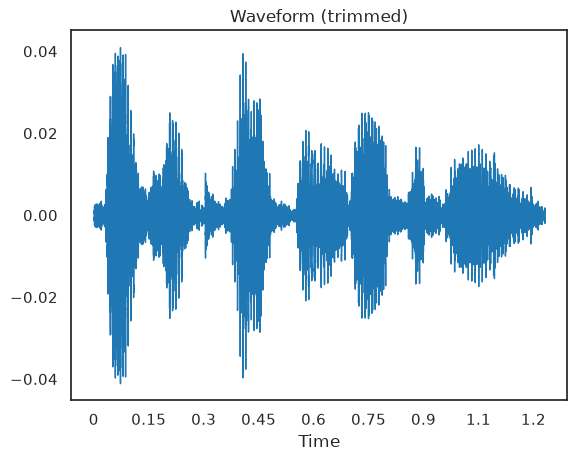

In [ ]:
# Plot trimmed waveform
librosa.display.waveshow(y_trmd, sr=sr)
plt.title("Waveform (trimmed)")

<Axes: >

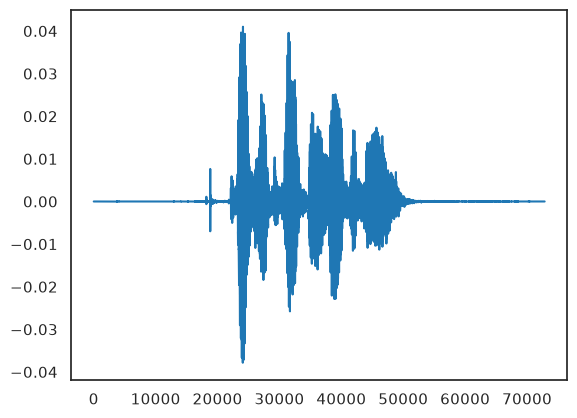

In [ ]:
sns.lineplot(data= pd.Series(y))

(array([[1.45329157e-10, 1.52943303e-09, 6.10540599e-08, ...,
         1.60910835e-05, 1.13747644e-05, 1.10594305e-05],
        [8.00796299e-06, 2.63945262e-07, 5.19903563e-07, ...,
         5.28731852e-05, 3.38089795e-05, 2.40003496e-05],
        [3.75699030e-06, 1.67061725e-07, 3.46155139e-07, ...,
         3.10655245e-05, 1.22067481e-05, 2.70336175e-07],
        ...,
        [1.51553902e-09, 3.70672148e-10, 7.86168400e-11, ...,
         1.40842696e-12, 5.07299587e-13, 4.94364311e-13],
        [4.58633142e-11, 6.52512497e-11, 5.35730444e-13, ...,
         6.99395686e-15, 2.50610678e-14, 3.93281118e-14],
        [4.91341206e-12, 3.52204555e-12, 1.02472656e-13, ...,
         4.20744533e-16, 7.87733745e-17, 2.50053099e-15]], shape=(129, 211)),
 array([0.       , 0.0078125, 0.015625 , 0.0234375, 0.03125  , 0.0390625,
        0.046875 , 0.0546875, 0.0625   , 0.0703125, 0.078125 , 0.0859375,
        0.09375  , 0.1015625, 0.109375 , 0.1171875, 0.125    , 0.1328125,
        0.140625 , 0.1484

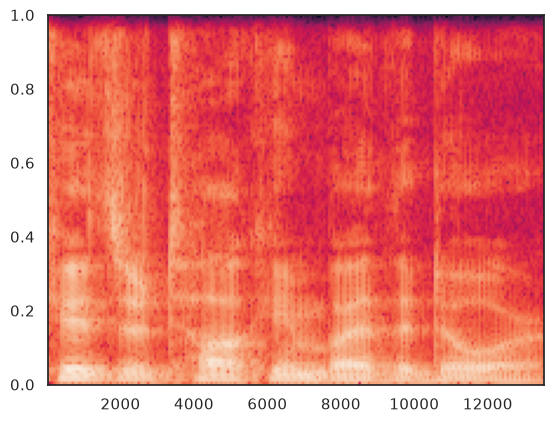

In [8]:
y_trmd, _ = librosa.effects.trim(y, top_db=20)
plt.specgram(pd.Series(y_trmd))

Text(0.5, 1.0, 'Zoomed-in Waveform')

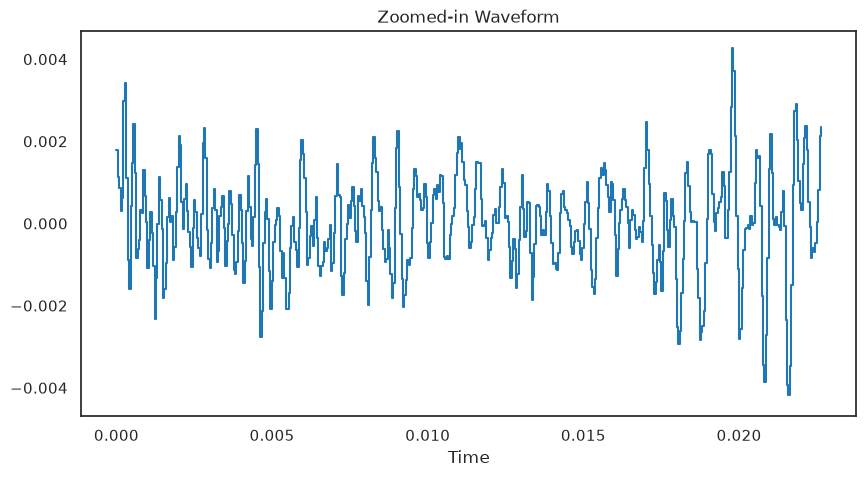

In [16]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(10, 5))
librosa.display.waveshow(y[30000:30500], )
ax.set_title("Zoomed-in Waveform")

### SPECTROGRAM

Text(0.5, 1.0, 'Spectrogram (dB)')

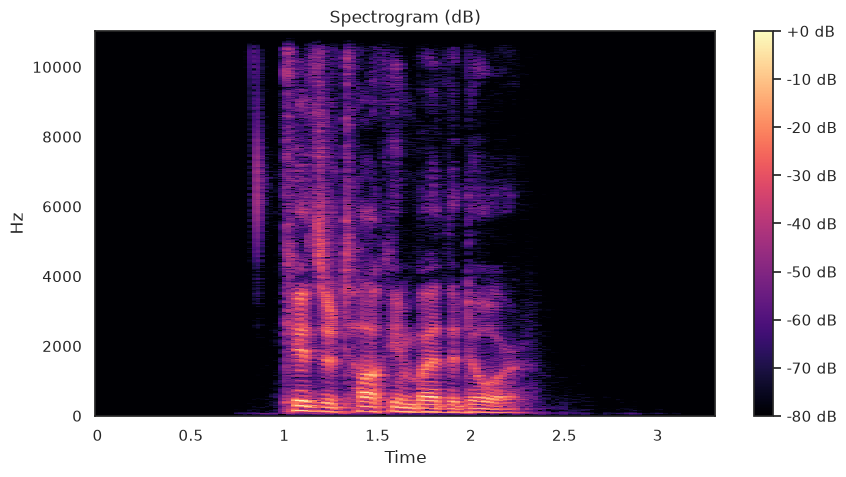

In [18]:
D = librosa.stft(y)
s_db = librosa.amplitude_to_db(np.abs(D), ref=np.max) #basically for normalizing the values to a range of 0 to 1
plt.figure(figsize=(10, 5))
librosa.display.specshow(s_db, sr=sr, x_axis='time', y_axis='hz')
plt.colorbar(format='%+2.0f dB')
plt.title('Spectrogram (dB)')

In [20]:
import os
print(os.environ.get('CUDA'))

None


```text 
ASR (Automatic Speech Recognition) voice metrics are the standards used to evaluate how accurately, quickly, and efficiently a speech-to-text model converts audio into text. They are crucial for measuring voice agent performance, live captioning, and conversational AI. [1, 2, 3, 4, 5]  
```

The most vital ASR performance metrics include: 
1. Accuracy Metrics 

	• Word Error Rate (WER): The primary industry-standard metric. It calculates the proportion of mistakes by dividing the sum of insertions, deletions, and substitutions by the total number of words spoken. 

	Formula: 
	$\text{WER} = \frac{\text{Substitutions} + \text{Deletions} + \text{Insertions}}{\text{Total Words}} \times 100$ 

	• Target: Less than 5% for enterprise-grade production. [6, 7, 8]  

	• Character Error Rate (CER): Similar to WER, but tracks individual character edits rather than full words. Useful for languages with complex orthographies or highly inflective words. 
	• Concept Error Rate (ConER): Measures the rate at which the meaning or intent of a sentence is lost, bypassing literal typos. [13]  

2. Latency Metrics 

	• Real-Time Factor (RTFx): Measures how fast an ASR system processes audio relative to the length of the audio file. 

	• RTFx &gt; 1.0 (Faster than real-time good for streaming). \
	• RTFx = 1.0 (Exactly real-time). \
	• RTFx &lt; 1.0 (Slower than real-time). [14, 15, 16]  

	• Time to First Token (TTFT): For live voice bots, this measures the exact time it takes from when a user finishes speaking to when the ASR system starts processing and returning words. Targets are usually strictly capped around &lt; 250 ms to prevent dead air. [17, 18, 19]  

3. Pipeline Metrics (End-to-End) 
In production, ASR rarely lives in isolation. These metrics measure how the voice text interacts with downstream systems: 

• Task Success Rate (TSR): Whether the voice agent or transcription system achieved the intended user goal. 
• End-of-Turn Detection: How reliably the ASR knows a user has finished speaking to prevent unnatural waiting or aggressive interruptions. [7, 17]  

In [40]:
import numpy as np
def levenshtein_distance(ref, hyp):
    """Calculate the Levenshtien distance between two sequences; eg adarsh and darsh would have a distance of 1 because of the extra 'a' in adarsh."""
    m, n = len(ref), len(hyp)
    if ref == hyp:
        return 0
    if m == 0:
        return n
    if n == 0:
        return m
    
    if m < n :
        ref, hyp = hyp , ref
        m , n = n, m
        
    previous_row = range(n + 1)
    for i, c1 in enumerate(ref):
        current_row = [ i + 1]
        for j , c2 in enumerate(hyp):
            insertions = previous_row[ j + 1] + 1
            deletions = current_row[j] + 1
            substitutions = previous_row[j] + (c1 != c2)
            current_row.append(min(insertions, deletions, substitutions))
            
        previous_row = current_row
    return previous_row[-1]

def normalize_text(text, ignore_case = False, remove_space = False):
    """Normalize text based on the specified conditions."""
    if ignore_case:
        text = text.lower()
    if remove_space:
        text = ''.join(text.split())
    return text

def calculate_errors(reference, hypothesis, ignore_case=False, remove_space=False, delimiter=None):
    """Calculates edit distance and length/reference length based on the mode (word or char level)."""
    reference = normalize_text(reference, ignore_case, remove_space)
    hypothesis = normalize_text(hypothesis, ignore_case, remove_space)

    if delimiter:
        reference = reference.split(delimiter)
        hypothesis = hypothesis.split(delimiter)

    edit_distance = levenshtein_distance(reference, hypothesis)
    ref_len = len(reference)

    return float(edit_distance), ref_len

def wer(reference, hypothesis, ignore_case=False, delimiter=' '): #word error rate
    """Calculates word error rate."""
    edit_distance, ref_len = calculate_errors(reference, hypothesis, ignore_case, False, delimiter)

    if ref_len == 0:
        raise ValueError("Reference's word number should be greater than 0.")

    return edit_distance / ref_len

def cer(reference, hypothesis, ignore_case=False, remove_space=False): #character error rate
    """Calculates character error rate."""
    edit_distance, ref_len = calculate_errors(reference, hypothesis, ignore_case, remove_space)
    if ref_len == 0:
        raise ValueError("Length of reference should be greater than 0.")
    return edit_distance / ref_len

In [41]:
# levenshtein_distance("adarsh", "darsh")
display(normalize_text("ADARSH", ignore_case=True, remove_space=True))
display(calculate_errors("ADARSH", "DARSH", ignore_case=True, remove_space=True))

display(wer("hello world", "hello word", ignore_case=True))
display(cer("hello world", "hello word", ignore_case=True, remove_space=True))

'adarsh'

(1.0, 6)

0.5

0.1

In [45]:
reference = 'Hello My Name is Hakim'
hypothesis = 'Hello My Neim is Hakim'

print(f"WER: {wer(reference, hypothesis, ignore_case=True)}")
print(f"CER: {cer(reference, hypothesis, ignore_case=True, remove_space=True)}")

WER: 0.2
CER: 0.16666666666666666:.2%


In [60]:
import string 
from itertools import dropwhile

def get_chars(text):
    additional_chars = ["''", '<SPACE>']
    all_chars = additional_chars + list(string.ascii_lowercase)
    return {char:i for char,i in enumerate(all_chars) if char in normalize_text(text, ignore_case=True, remove_space=True)}


In [79]:
import string
from itertools import dropwhile

class TextTransform:
    """Maps characters to integers and vice verse, using the string module for cahracter definitions"""
    def __init__(self):
        additional_chars = ["''", '<SPACE>']
        all_chars = additional_chars + list(string.ascii_lowercase) #list of all the chars
        self.char_map = {char: i for i, char in enumerate(all_chars)}

        # Inverting char_map to crate index_map
        self.index_map = {index: char for char, index in self.char_map.items()}
        self.index_map[self.char_map['<SPACE>']] = ' ' 
        
    def text_to_int(self, text):
        '''Converts text to an interger sequences using a character map'''
        return [self.char_map.get(c, self.char_map['<SPACE>']) for c in text.lower()]
    
    def int_to_text(self, labels):
        '''converts integer labels to a text sequence using a character map'''
        return ''.join(self.index_map[i] for i in labels).replace('<SPACE>', ' ')
    
    def int_to_text_remove_pad(self, int_sequence):
        # Remove trailing zeros which are used for padding
        # This is done by reversing the list, using itertools.dropwhile to drop the zeros,
        # and then reversing the list back to the original order

        # Reverse, remove zeros from the end (now start), and reverse back
        text_sequence = list(dropwhile(lambda x: x == 0, reversed(int_sequence)))[::-1]

        # Convert the non-padded sequence to text
        text = ''.join(self.index_map[i] for i in text_sequence).replace('<SPACE>', ' ')
        return text
    

In [77]:
def get_chars(text):
    additional_chars = ["''", '<SPACE>', ' ']
    all_chars = additional_chars + list(string.ascii_lowercase)
    print(f"all chars: {all_chars}")
    normalized = normalize_text(text, ignore_case=True, remove_space=True)
    chars=  {char: i for i, char in enumerate(all_chars) if char in normalized}
    return chars

In [78]:
get_chars("Adarsh" )

all chars: ["''", '<SPACE>', ' ', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']


{'a': 3, 'd': 6, 'h': 10, 'r': 20, 's': 21}

In [80]:
test = TextTransform()

In [98]:
test_int = test.text_to_int("Adarsh Kr Shah")
int_text = test.int_to_text(test_int)
display(test_int, int_text)


[2, 5, 2, 19, 20, 9, 1, 12, 19, 1, 20, 9, 2, 9]

'adarsh kr shah'

In [94]:
int_text

[2, 5, 2, 19, 20, 9, 1, 12, 19, 1, 20, 9, 2, 9]

### Padding and Normalization

```text
Padding and normalization are crucial preprocessing steps in ASR systems to ensure that audio data is in a consistent format for model training and inference.
``` 
1. Padding: Since audio samples can vary in length, padding is used to make all samples the same length. This is typically done by adding zeros to the end of shorter audio sequences until they match the length of the longest sequence in a batch. This allows for efficient batch processing and ensures that the model can handle variable-length inputs without issues. [9, 10]
    - Batch Processing: Machine learning models process data in fixed-size arrays (tensors). Padding allows sentences of varying lengths to be grouped together in uniform batches, drastically speeding up training and inference.
    - Parallelization: By enforcing uniform lengths across all sequences, hardware like GPUs and TPUs can perform matrix operations in parallel instead of one at a time.Architecture 
    - Compatibility: Layers in deep learning models—such as Recurrent Neural Networks (RNNs), LSTMs, and Dense layers—require input tensors with matching shapes. Padding ensures these mathematical operations do not throw dimension-mismatch errors.

2. Normalization: This process involves scaling the audio data to a standard range, often between -1 and 1. Normalization helps to reduce the impact of varying recording conditions, such as different microphone sensitivities or background noise levels, and can improve the convergence of the model during training. [11, 12]

In [104]:
import torch
import torch.nn as nn

torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

text_transform = TextTransform()

texts = ["Hello world", "My name is Adarsh Kumar"]
labels = [torch.Tensor(text_transform.text_to_int(text)) for text in texts]
labels = nn.utils.rnn.pad_sequence(labels, batch_first=True)
labels

tensor([[ 9.,  6., 13., 13., 16.,  1., 24., 16., 19., 13.,  5.,  0.,  0.,  0.,
          0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.],
        [14., 26.,  1., 15.,  2., 14.,  6.,  1., 10., 20.,  1.,  2.,  5.,  2.,
         19., 20.,  9.,  1., 12., 22., 14.,  2., 19.]])

In [116]:
text_transform.int_to_text([int(i) for i in (labels[0])])
text_transform.int_to_text([int(i) for i in (labels[1])])

'my name is adarsh kumar'

(array([ 5.3765323e-08, -2.1233109e-08, -6.0478840e-09, ...,
         1.9131086e-15,  4.2487444e-14,  5.9047873e-14],
       shape=(72838,), dtype=float32),
 22050)

In [ ]:
def valid_audio_transforms(waveform, sample_rate=16000, n_mels=128, n_fft=2048, hop_length=512):
    if hasattr(waveform, "numpy"):
        waveform = waveform.numpy()
    waveform = waveform.squeeze()
    mel_spec = librosa.feature.melspectrogram(
        y=waveform,
        sr=sample_rate,
        n_fft=n_fft,
        hop_length=hop_length,
        n_mels=n_mels,
        power=2.0,
    )
    return librosa.power_to_db(mel_spec, ref=np.max)

def frequency_mask(spec, freq_mask_param=30):
    spec = spec.copy()
    num_mel_channels = spec.shape[0]
    f = np.random.randint(0, freq_mask_param + 1)
    if f == 0:
        return spec
    f0 = np.random.randint(0, num_mel_channels - f + 1)
    spec[f0:f0 + f, :] = spec.min()
    return spec

def time_mask(spec, time_mask_param=100):
    spec = spec.copy()
    t = np.random.randint(0, time_mask_param + 1)
    if t == 0:
        return spec
    t0 = np.random.randint(0, spec.shape[1] - t + 1)
    spec[:, t0:t0 + t] = spec.min()
    return spec

audio_vec = librosa.load(audio_files[0])

waveform, sample_rate, utterance, speaker_id, chapter_id, utterance_id = audio_vec
spec = valid_audio_transforms(waveform, sample_rate=sample_rate)
spec = frequency_mask(spec, freq_mask_param=30)
spec = time_mask(spec, time_mask_param=100)
spec = spec.T
spec.shape

valid_audio_transforms = torchaudio.transforms.MelSpectrogram()

waveform, sample_rate, utterance, speaker_id, chapter_id, utterance_id = librosa.load(audio_files[0])
spec = train_audio_transforms(waveform).squeeze(0).transpose(0, 1)
spec.shape